# ЛР07. Построение автокодировщика

**Вариант 7:** набор сцен №2 `disc_rect` — «диск и полоса» (4 фактора сцены); фактор №1 — размер латентного вектора, d = 8 → 2; seed 101…105.

## Гипотеза и допуск — зафиксированы до запуска (27.10.2026 19:05)

**Гипотеза.** Сцена задаётся четырьмя независимыми факторами (положение диска по x и y, радиус диска, положение полосы), поэтому два числа не могут закодировать её полностью: PSNR на тесте упадёт больше чем на 1 дБ, и сильнее, чем в демо-варианте с тремя факторами (−2,8 дБ). Разрыв train − test изменится в пределах ±0,1 дБ: потеря связана с ёмкостью узкого места, а не с переобучением. Время обучения изменится в пределах ±20 %. Оба режима будут лучше эталона «средняя картинка».

**Допуск.** PSNR — ±1,0 дБ; разрыв train − test — ±0,1 дБ; время — ±20 % от режима A. Число параметров детерминировано (84 643 + 2049·d), класс по допуску для него не назначается.

**Классификация вне допуска.** PSNR: рост — улучшение. Разрыв: рост — ухудшение. Время: рост — ухудшение.

PSNR считается на тестовой выборке и сравнивается с эталоном «средняя картинка». Вывод делается только после измерения и только для проверенных условий.

In [1]:
# Проверка GPU и фактических версий. Серию из пяти seed на процессоре не запускают.
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip list 2>/dev/null | grep -i -E "^(torch|numpy|pillow|matplotlib|pandas) "

import json, pathlib, platform, shutil, sys, time
from datetime import datetime, timezone
import numpy as np, torch, PIL

assert torch.cuda.is_available(), "CUDA GPU недоступен: выберите GPU T4 в настройках Colab"
environment = {
    "execution_environment": "Google Colab",
    "gpu": torch.cuda.get_device_name(0),
    "cuda_available": torch.cuda.is_available(),
    "cuda_runtime": torch.version.cuda,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "packages": {"torch": torch.__version__, "numpy": np.__version__, "pillow": PIL.__version__},
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
}
print(json.dumps(environment, ensure_ascii=False, indent=2))

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
matplotlib                            3.10.0
numpy                                 2.1.3
pandas                                2.2.3
pillow                                11.3.0
torch                                 2.11.0+cu130
{
  "execution_environment": "Google Colab",
  "gpu": "Tesla T4",
  "cuda_available": true,
  "cuda_runtime": "13.0",
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "packages": {
    "torch": "2.11.0+cu130",
    "numpy": "2.1.3",
    "pillow": "11.3.0"
  },
  "started_at_utc": "2026-10-27T17:20:48.606664+00:00"
}


In [2]:
%%writefile lab07_lib.py
# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model


@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Writing lab07_lib.py


In [3]:
%%writefile lab07_demo.py
# ЛР 7. Демонстрационный вариант 1: набор «диск», фактор «размер латентного вектора 8 → 2».
import numpy as np
import lab07_lib as L

N = 1
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = L.settings(L.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)

# Серия из пяти seed: метрики режимов A и B
result = L.variant_summary(N)
for name, a, s, b, d, q, sig in result["rows"]:
    print(f"{name:8s} A={a:8.3f} s={s:6.3f} B={b:8.3f} d={d:+8.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

# Тривиальный эталон: средняя картинка обучающей выборки, одинаковая для всех входов
Xtr, Xte, Ftr, Fte = L.dataset(L.KINDS[c])
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
print("эталон «средняя картинка», PSNR на тесте:", round(L.psnr_images(mean_image, Xte), 3))

# Диагностика: PSNR в зависимости от размера латентного вектора (seed 101, 102, 103)
for d in (1, 2, 3, 4, 8):
    vals = [L.run(L.KINDS[c], dict(L.BASE, d=d), s)[0]["psnr"] for s in (101, 102, 103)]
    print(f"d={d}: PSNR = {np.mean(vals):.2f} дБ (по seed: {', '.join(f'{v:.2f}' for v in vals)})")

# Лист сравнения comparison.png: оригиналы, реконструкции режима A и режима B (seed 101, первые 8 тестовых сцен)
from PIL import Image
rows = [Xte[:8]]
for cfg in (a_cfg, b_cfg):
    model = L.run(L.KINDS[c], cfg, 101)[1]
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))
grid = np.concatenate([np.concatenate(list(r.permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows], axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize((8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet


Writing lab07_demo.py


In [4]:
# Фиксированные параметры варианта (совпадают с configs/run_config.json) и сверка библиотек.
import hashlib, math
import pandas as pd
from IPython.display import display
from IPython.utils.capture import capture_output
from PIL import Image
import lab07_lib as L

VARIANT = 7
DATASET = 2
KIND = "disc_rect"
FACTOR = "latent_8_to_2"
SEEDS = [101, 102, 103, 104, 105]
SWEEP_D, SWEEP_SEEDS = [1, 2, 3, 4, 8], [101, 102, 103]
TOLERANCE = {"psnr": ("abs", 1.0), "gap": ("abs", 0.1), "seconds": ("rel", 0.20)}
DIRECTION = {"psnr": +1, "gap": -1, "seconds": -1}  # +1: рост — улучшение, -1: рост — ухудшение
HYPOTHESIS_RECORDED_AT = "27.10.2026 19:05"
EXPECTED_SHA256 = {
    "lab07_lib.py": "d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698",
    "lab07_demo.py": "fce7924908adbef63dd5808a800a3c9f5b96c137dc9ebf9d398fc2eb613d95fa",
}

CTX, FAC = (VARIANT - 1) // 6, (VARIANT - 1) % 6
assert (CTX + 1, L.KINDS[CTX], L.FACTORS[FAC]) == (DATASET, KIND, FACTOR)
assert list(L.SEEDS) == SEEDS and L.N_FACTORS[KIND] == 4

library_sha256 = {name: hashlib.sha256(pathlib.Path(name).read_bytes()).hexdigest() for name in EXPECTED_SHA256}
assert library_sha256 == EXPECTED_SHA256, library_sha256

A_CFG, B_CFG = L.settings(FACTOR)
changed = sorted(key for key in A_CFG if A_CFG[key] != B_CFG[key])
assert changed == ["d"], changed

root = pathlib.Path(".")
artifacts = root / "artifacts"
reports = root / "reports"
for path in [artifacts / "demo", reports]:
    path.mkdir(parents=True, exist_ok=True)

print("Устройство:", L.DEVICE)
print("Режим A:", A_CFG)
print("Режим B:", B_CFG)
print("Изменённое поле:", changed)
print("SHA-256 библиотек совпали с методичкой:", library_sha256 == EXPECTED_SHA256)

Устройство: cuda
Режим A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
Режим B: {'arch': 'conv', 'd': 2, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
Изменённое поле: ['d']
SHA-256 библиотек совпали с методичкой: True


## Демонстрационный вариант 1

Код `lab07_demo.py` из раздела 6.2 методички выполняется без изменений: набор «диск» × d = 8 → 2, эталон «средняя картинка», развёртка по d и лист сравнения. Затем результат сверяется с разделами 6.3–6.4 методички.

A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
B: {'arch': 'conv', 'd': 2, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
psnr     A=  26.012 s= 0.692 B=  23.192 d=  -2.820 |d|/s=   4.07 2s=да
gap      A=   0.034 s= 0.016 B=   0.097 d=  +0.063 |d|/s=   4.08 2s=да
params   A= 101.035 s= 0.000 B=  88.741 d= -12.294 |d|/s=    inf 2s=да
seconds  A=   1.969 s= 0.093 B=   1.909 d=  -0.059 |d|/s=   0.64 2s=нет
эталон «средняя картинка», PSNR на тесте: 17.171
d=1: PSNR = 20.64 дБ (по seed: 20.64, 20.73, 20.53)
d=2: PSNR = 23.16 дБ (по seed: 23.31, 23.42, 22.74)
d=3: PSNR = 25.21 дБ (по seed: 24.74, 24.61, 26.28)
d=4: PSNR = 26.46 дБ (по seed: 27.05, 26.12, 26.21)
d=8: PSNR = 25.77 дБ (по seed: 25.63, 26.62, 25.08)


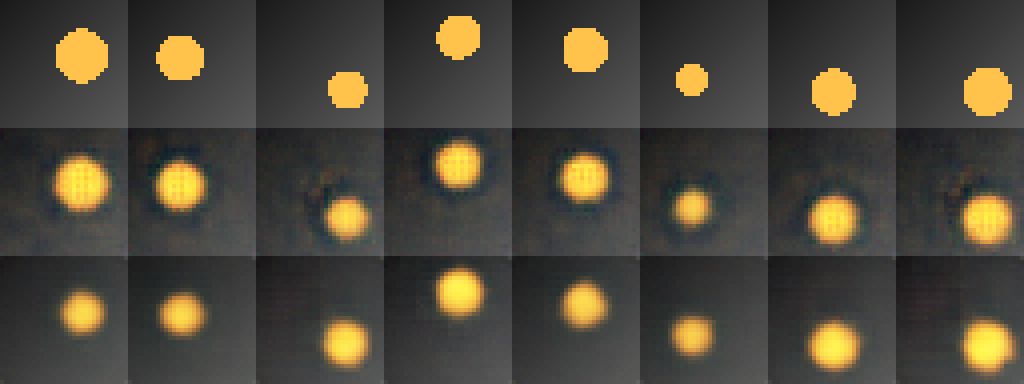

{'demo_seconds': 68.1}


In [5]:
# Демонстрационный вариант 1: lab07_demo.py выполняется целиком; вывод сохраняется в artifacts/demo/.
demo_started = time.perf_counter()
with capture_output() as demo_capture:
    get_ipython().run_line_magic("run", "lab07_demo.py")
demo_seconds = time.perf_counter() - demo_started
demo_capture.show()
(artifacts / "demo" / "demo_output.txt").write_text(demo_capture.stdout, encoding="utf-8")
shutil.move("comparison.png", artifacts / "demo" / "comparison_variant01.png")
display(Image.open(artifacts / "demo" / "comparison_variant01.png"))
print({"demo_seconds": round(demo_seconds, 2)})

In [6]:
# Сверка демонстрационного варианта с таблицей 6.3 и развёрткой 6.4 методички.
import re

def jnum(value):
    return value if math.isfinite(value) else ("inf" if value > 0 else "-inf")

DEMO_REFERENCE = {  # A, s, B, Δ из таблицы 6.3
    "psnr": (26.00, 0.71, 23.20, -2.80),
    "gap": (0.040, 0.013, 0.101, 0.061),
    "params": (101.0, 0.0, 88.7, -12.3),
    "seconds": (2.27, 0.28, 2.10, -0.17),
}
DEMO_SWEEP_REFERENCE = {1: 20.64, 2: 23.16, 3: 25.24, 4: 26.45, 8: 25.70}
DEMO_BASELINE_REFERENCE = 17.171

demo_rows = []
for name, a, s, b, d, q, sig in result["rows"]:
    ra, rs, rb, rd = DEMO_REFERENCE[name]
    demo_rows.append({"metric": name, "A": a, "s": s, "B": b, "d": d, "ratio": jnum(q), "sig_2s": sig,
                      "A_ref": ra, "s_ref": rs, "B_ref": rb, "d_ref": rd,
                      "A_within_2s_ref": name != "seconds" and abs(a - ra) <= max(2 * rs, 0.05),
                      "B_within_2s_ref": name != "seconds" and abs(b - rb) <= max(2 * rs, 0.05)})
demo_sweep = {int(d): float(v) for d, v in re.findall(r"d=(\d+): PSNR = ([\d.]+)", demo_capture.stdout)}
demo_baseline = float(re.search(r"PSNR на тесте: ([\d.]+)", demo_capture.stdout).group(1))
assert sorted(demo_sweep) == SWEEP_D
demo_result = {
    "variant": result["variant"], "factor": result["factor"], "rows": demo_rows,
    "baseline_psnr": demo_baseline, "baseline_reference": DEMO_BASELINE_REFERENCE,
    "sweep": {str(d): {"psnr": demo_sweep[d], "reference": DEMO_SWEEP_REFERENCE[d]} for d in SWEEP_D},
    "demo_seconds": round(demo_seconds, 2),
}
(artifacts / "demo" / "demo_variant01.json").write_text(
    json.dumps(demo_result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame(demo_rows).round(3))
display(pd.DataFrame([{"d": d, "PSNR": demo_sweep[d], "методичка": DEMO_SWEEP_REFERENCE[d]} for d in SWEEP_D]))
print("эталон «средняя картинка»:", demo_baseline, "| методичка:", DEMO_BASELINE_REFERENCE)
print("Обучение на GPU не побитово детерминировано: сверяется картина в пределах разброса между seed, а не последний знак.")

,metric,A,s,B,d,ratio,sig_2s,A_ref,s_ref,B_ref,d_ref,A_within_2s_ref,B_within_2s_ref
0,psnr,26.012,0.692,23.192,-2.820,4.071809,True,26.00,0.710,23.200,-2.800,True,True
1,gap,0.034,0.016,0.097,0.063,4.075969,True,0.04,0.013,0.101,0.061,True,True
2,params,101.035,0.000,88.741,-12.294,inf,True,101.00,0.000,88.700,-12.300,True,True
3,seconds,1.969,0.093,1.909,-0.059,0.635161,False,2.27,0.280,2.100,-0.170,False,False


,d,PSNR,методичка
0,1,20.64,20.64
1,2,23.16,23.16
2,3,25.21,25.24
3,4,26.46,26.45
4,8,25.77,25.70


эталон «средняя картинка»: 17.171 | методичка: 17.171
Обучение на GPU не побитово детерминировано: сверяется картина в пределах разброса между seed, а не последний знак.


## Вариант 7: «диск и полоса» × d = 8 → 2

In [7]:
# Обязательный вызов из методички: L.variant_summary(7). Обёртка над L.run только записывает метрики каждого запуска.
run_log = []
_original_run = L.run

def _logged_run(kind, cfg, seed):
    metrics, model = _original_run(kind, cfg, seed)
    run_log.append({"d": cfg["d"], "seed": seed, **metrics})
    return metrics, model

L.run = _logged_run
try:
    summary_started = time.perf_counter()
    summary = L.variant_summary(VARIANT)
    summary_seconds = time.perf_counter() - summary_started
finally:
    L.run = _original_run
assert summary["variant"] == VARIANT and summary["ctx"] == DATASET and summary["factor"] == FACTOR

print("Вариант", summary["variant"], "набор", KIND, "фактор", summary["factor"])
for name, a, s, b, d, q, sig in summary["rows"]:
    print(f"{name:8s} A={a:8.3f} s={s:6.3f} B={b:8.3f} d={d:+8.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

METRIC_NAMES = {"psnr": "PSNR на тесте, дБ", "gap": "разрыв train − test, дБ", "params": "параметры, тыс.", "seconds": "время обучения, с"}
metric_rows = [{"metric": m, "A": a, "s": s, "B": b, "d": d, "ratio": jnum(q), "sig_2s": sig}
               for m, a, s, b, d, q, sig in summary["rows"]]

per_seed_df = pd.DataFrame([dict(row, mode="A" if row["d"] == A_CFG["d"] else "B") for row in run_log if row["seed"] in SEEDS])
per_seed_df = per_seed_df[["mode", "seed", "d", "psnr", "gap", "params", "seconds"]]
per_seed_df.to_csv(artifacts / "per_seed_metrics.csv", index=False)
for m, a, s, b, *_ in summary["rows"]:
    assert np.isclose(np.mean(per_seed_df[per_seed_df["mode"] == "A"][m]), a) and np.isclose(np.mean(per_seed_df[per_seed_df["mode"] == "B"][m]), b)

metrics = {"variant": VARIANT, "dataset": KIND, "factor": FACTOR, "seeds": SEEDS, "mode_a": A_CFG, "mode_b": B_CFG,
           "rows": metric_rows, "summary_seconds": round(summary_seconds, 2)}
(artifacts / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame([{"метрика": METRIC_NAMES[r["metric"]], "A (d = 8)": r["A"], "s": r["s"], "B (d = 2)": r["B"], "Δ": r["d"],
                       "|Δ|/s": r["ratio"] if r["metric"] != "params" else "—", "|Δ| > 2s": "да" if r["sig_2s"] else "нет"}
                      for r in metric_rows]).round(3))
display(per_seed_df.round(3))

Вариант 7 набор disc_rect фактор latent_8_to_2
psnr     A=  26.193 s= 0.628 B=  20.603 d=  -5.590 |d|/s=   8.90 2s=да
gap      A=   0.043 s= 0.007 B=  -0.000 d=  -0.043 |d|/s=   6.26 2s=да
params   A= 101.035 s= 0.000 B=  88.741 d= -12.294 |d|/s=    inf 2s=да
seconds  A=   1.922 s= 0.040 B=   1.903 d=  -0.019 |d|/s=   0.47 2s=нет


,метрика,A (d = 8),s,B (d = 2),Δ,|Δ|/s,|Δ| > 2s
0,"PSNR на тесте, дБ",26.193,0.628,20.603,-5.590,8.901813,да
1,"разрыв train − test, дБ",0.043,0.007,-0.000,-0.043,6.258192,да
2,"параметры, тыс.",101.035,0.000,88.741,-12.294,—,да
3,"время обучения, с",1.922,0.040,1.903,-0.019,0.469261,нет


,mode,seed,d,psnr,gap,params,seconds
0,A,101,8,26.383,0.048,101.035,1.920
1,B,101,2,20.616,-0.014,88.741,1.883
2,A,102,8,26.668,0.043,101.035,1.920
3,B,102,2,20.658,0.009,88.741,1.961
4,A,103,8,25.142,0.044,101.035,1.913
5,B,103,2,20.629,-0.002,88.741,1.903
6,A,104,8,26.646,0.047,101.035,1.983
7,B,104,2,20.466,-0.003,88.741,1.898
8,A,105,8,26.126,0.031,101.035,1.872
9,B,105,2,20.647,0.008,88.741,1.871


эталон «средняя картинка», PSNR на тесте: 16.892
выигрыш над эталоном: A = +9.30 дБ, B = +3.71 дБ


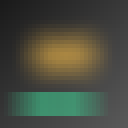

In [8]:
# Эталон «средняя картинка» для набора варианта: средняя обучающая сцена, одинаковая для всех входов.
Xtr, Xte, Ftr, Fte = L.dataset(KIND)
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
baseline_psnr = L.psnr_images(mean_image, Xte)
psnr_a, psnr_b = metric_rows[0]["A"], metric_rows[0]["B"]
baseline = {"dataset": KIND, "baseline_psnr": baseline_psnr,
            "gain_a_db": psnr_a - baseline_psnr, "gain_b_db": psnr_b - baseline_psnr}
(artifacts / "baseline.json").write_text(json.dumps(baseline, ensure_ascii=False, indent=2), encoding="utf-8")
print("эталон «средняя картинка», PSNR на тесте:", round(baseline_psnr, 3))
print(f"выигрыш над эталоном: A = {baseline['gain_a_db']:+.2f} дБ, B = {baseline['gain_b_db']:+.2f} дБ")
mean_image_png = (Xtr.mean(0).permute(1, 2, 0).cpu().numpy() * 255).round().astype("uint8")
Image.fromarray(mean_image_png).resize((128, 128), Image.NEAREST).save(artifacts / "mean_image.png")
display(Image.open(artifacts / "mean_image.png"))

d=1: PSNR = 19.42 дБ (по seed: 19.50, 19.53, 19.22)
d=2: PSNR = 20.60 дБ (по seed: 20.61, 20.67, 20.53)
d=3: PSNR = 22.08 дБ (по seed: 22.82, 21.68, 21.73)
d=4: PSNR = 22.98 дБ (по seed: 25.22, 21.74, 21.97)
d=8: PSNR = 26.01 дБ (по seed: 26.35, 26.53, 25.15)


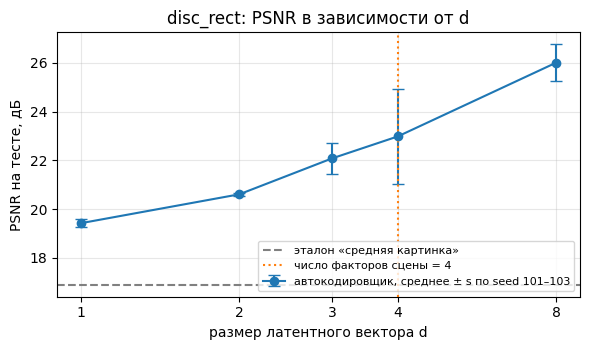

In [9]:
# Диагностика: PSNR в зависимости от размера латентного вектора для набора варианта (seed 101, 102, 103).
import matplotlib.pyplot as plt

sweep = {}
for d in SWEEP_D:
    vals = [L.run(KIND, dict(L.BASE, d=d), s)[0]["psnr"] for s in SWEEP_SEEDS]
    sweep[d] = vals
    print(f"d={d}: PSNR = {np.mean(vals):.2f} дБ (по seed: {', '.join(f'{v:.2f}' for v in vals)})")
(artifacts / "latent_sweep.json").write_text(json.dumps(
    {"dataset": KIND, "seeds": SWEEP_SEEDS, "baseline_psnr": baseline_psnr,
     "psnr": {str(d): {"mean": float(np.mean(v)), "by_seed": v} for d, v in sweep.items()}}, ensure_ascii=False, indent=2), encoding="utf-8")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(SWEEP_D, [np.mean(sweep[d]) for d in SWEEP_D], yerr=[np.std(sweep[d], ddof=1) for d in SWEEP_D],
            marker="o", capsize=4, label="автокодировщик, среднее ± s по seed 101–103")
ax.axhline(baseline_psnr, color="gray", linestyle="--", label="эталон «средняя картинка»")
ax.axvline(L.N_FACTORS[KIND], color="tab:orange", linestyle=":", label="число факторов сцены = 4")
ax.set_xscale("log", base=2); ax.set_xticks(SWEEP_D); ax.set_xticklabels(SWEEP_D)
ax.set_xlabel("размер латентного вектора d"); ax.set_ylabel("PSNR на тесте, дБ")
ax.set_title("disc_rect: PSNR в зависимости от d"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(artifacts / "latent_sweep.png", dpi=150); plt.show()

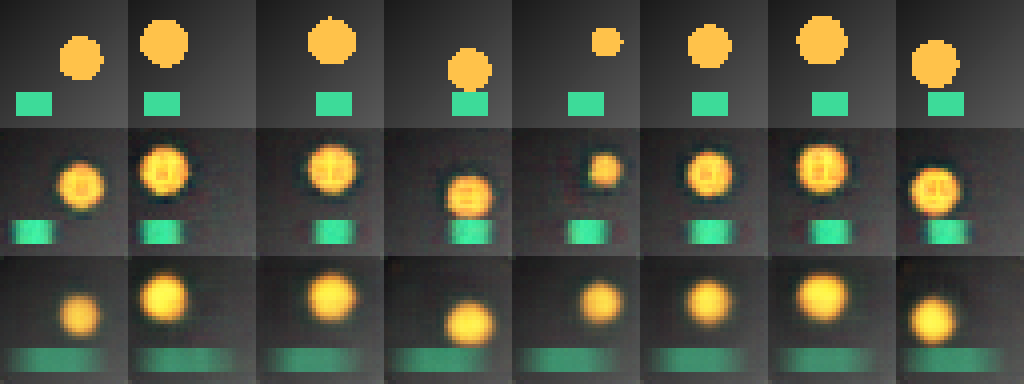

In [10]:
# Лист сравнения comparison.png — код раздела 6.2 методички, N = 7: оригиналы, режим A, режим B (seed 101, первые 8 тестовых сцен).
N = 7
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = L.settings(L.FACTORS[k])
Xtr, Xte, Ftr, Fte = L.dataset(L.KINDS[c])
from PIL import Image
rows = [Xte[:8]]
for cfg in (a_cfg, b_cfg):
    model = L.run(L.KINDS[c], cfg, 101)[1]
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))
grid = np.concatenate([np.concatenate(list(r.permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows], axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize((8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet

In [11]:
# Копия comparison.png в artifacts/ и факторы восьми показанных тестовых сцен (для визуальной проверки).
shutil.copyfile("comparison.png", artifacts / "comparison.png")
sheet_psnr = {label: L.psnr_images(r, Xte[:8]) for label, r in (("A", rows[1]), ("B", rows[2]))}
scene_factors = pd.DataFrame(Fte[:8].cpu().numpy(), columns=["диск x", "диск y", "радиус", "полоса x"]).round(2)
scene_factors.index = [f"сцена {i + 1}" for i in range(8)]
scene_factors.to_csv(artifacts / "comparison_factors.csv")
display(scene_factors.T)
print("PSNR на восьми сценах листа:", {key: round(value, 2) for key, value in sheet_psnr.items()})

,сцена 1,сцена 2,сцена 3,сцена 4,сцена 5,сцена 6,сцена 7,сцена 8
диск x,0.77,0.06,0.69,0.84,1.00,0.59,0.34,0.10
диск y,0.62,0.12,0.08,0.98,0.09,0.24,0.05,0.80
радиус,0.71,0.90,0.89,0.65,0.05,0.68,0.99,0.88
полоса x,0.14,0.18,0.77,0.88,0.74,0.66,0.54,0.37


PSNR на восьми сценах листа: {'A': 25.75, 'B': 20.57}


In [12]:
# Классификация по заранее записанному допуску; сравнение с критерием 2s и чувствительность к допуску (×0.5, ×2).
def classify(metric, a, d, scale=1.0):
    kind, tol = TOLERANCE[metric]
    change = d if kind == "abs" else d / a
    if abs(change) <= tol * scale:
        return "нейтрально"
    return "улучшение" if change * DIRECTION[metric] > 0 else "ухудшение"

classification = []
for r in metric_rows:
    if r["metric"] not in TOLERANCE:
        continue
    kind, tol = TOLERANCE[r["metric"]]
    label = classify(r["metric"], r["A"], r["d"])
    classification.append({
        "metric": r["metric"], "change": r["d"] if kind == "abs" else r["d"] / r["A"], "change_kind": kind,
        "tolerance": tol, "class": label, "sig_2s": r["sig_2s"],
        "2s_and_tolerance_agree": r["sig_2s"] == (label != "нейтрально"),
        "class_tolerance_x0_5": classify(r["metric"], r["A"], r["d"], 0.5),
        "class_tolerance_x2": classify(r["metric"], r["A"], r["d"], 2.0),
    })
classes = {row["metric"]: row["class"] for row in classification}
params_row = next(r for r in metric_rows if r["metric"] == "params")
params_change = {"A_thousand": params_row["A"], "B_thousand": params_row["B"], "relative": params_row["d"] / params_row["A"]}
(artifacts / "classification.json").write_text(json.dumps(
    {"variant": VARIANT, "rows": classification, "params_change": params_change}, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame([{
    "метрика": METRIC_NAMES[row["metric"]],
    "изменение": f"{row['change']:+.3f}" if row["change_kind"] == "abs" else f"{row['change']:+.1%}",
    "допуск": f"±{row['tolerance']}" if row["change_kind"] == "abs" else f"±{row['tolerance']:.0%}",
    "класс": row["class"], "|Δ| > 2s": "да" if row["sig_2s"] else "нет",
    "2s и допуск согласуются": "да" if row["2s_and_tolerance_agree"] else "нет",
    "допуск ×0.5": row["class_tolerance_x0_5"], "допуск ×2": row["class_tolerance_x2"],
} for row in classification]))
print(f"параметры: {params_row['A']:.3f} → {params_row['B']:.3f} тыс. ({params_change['relative']:+.1%}), детерминировано")

,метрика,изменение,допуск,класс,|Δ| > 2s,2s и допуск согласуются,допуск ×0.5,допуск ×2
0,"PSNR на тесте, дБ",-5.590,±1.0,ухудшение,да,да,ухудшение,ухудшение
1,"разрыв train − test, дБ",-0.043,±0.1,нейтрально,да,нет,нейтрально,нейтрально
2,"время обучения, с",-1.0%,±20%,нейтрально,нет,да,нейтрально,нейтрально


параметры: 101.035 → 88.741 тыс. (-12.2%), детерминировано


## Ручная визуальная проверка

Посмотрите на `comparison.png`: верхняя строка — оригиналы восьми тестовых сцен, средняя — режим A (d = 8), нижняя — режим B (d = 2). Под листом выведены факторы этих сцен. Проверьте, что в каждом режиме восстанавливаются и диск, и полоса, а границы объектов не размываются; отметьте, какие факторы сцены режим B не передаёт (положение диска, радиус, положение полосы).

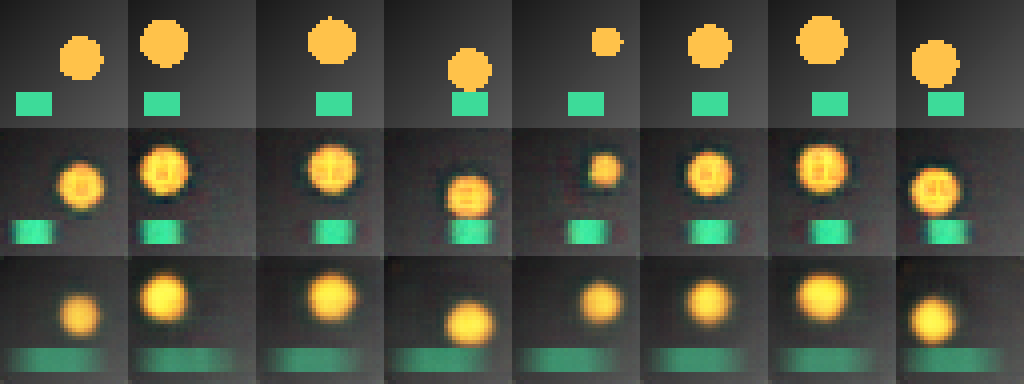

,сцена 1,сцена 2,сцена 3,сцена 4,сцена 5,сцена 6,сцена 7,сцена 8
диск x,0.77,0.06,0.69,0.84,1.00,0.59,0.34,0.10
диск y,0.62,0.12,0.08,0.98,0.09,0.24,0.05,0.80
радиус,0.71,0.90,0.89,0.65,0.05,0.68,0.99,0.88
полоса x,0.14,0.18,0.77,0.88,0.74,0.66,0.54,0.37


VISUAL_CHECK: {'a_disc_and_stripe_restored': True, 'b_disc_and_stripe_restored': False, 'b_lost_factors': ['полоса x', 'радиус'], 'notes': 'A: диск и полоса восстановлены во всех 8 сценах на своих местах, маленький диск сцены 5 остаётся маленьким; края размыты, внутри диска слабые тёмные артефакты. B: диск — размытое пятно примерно на своём месте, но почти одного размера во всех сценах (радиус не передаётся); полоса превратилась в бледную ленту через всю нижнюю часть кадра — её положение потеряно.'}


In [17]:
display(Image.open(artifacts / "comparison.png"))
display(scene_factors.T)

# Заполните только после фактического просмотра, затем перезапустите эту и последующие ячейки.
VISUAL_CHECK = {"a_disc_and_stripe_restored": True, "b_disc_and_stripe_restored": False, "b_lost_factors": ["полоса x", "радиус"], "notes": "A: диск и полоса восстановлены во всех 8 сценах на своих местах, маленький диск сцены 5 остаётся маленьким; края размыты, внутри диска слабые тёмные артефакты. B: диск — размытое пятно примерно на своём месте, но почти одного размера во всех сценах (радиус не передаётся); полоса превратилась в бледную ленту через всю нижнюю часть кадра — её положение потеряно."}
visual_done = (VISUAL_CHECK["a_disc_and_stripe_restored"] is not None
               and VISUAL_CHECK["b_disc_and_stripe_restored"] is not None and bool(VISUAL_CHECK["notes"]))
print("VISUAL_CHECK:", VISUAL_CHECK if visual_done else "PENDING")

In [18]:
# Намеренная ошибка (как в демо): «PSNR режима B выше 20 дБ — двух чисел достаточно». Проверка эталоном и развёрткой по d.
sweep_means = {d: float(np.mean(v)) for d, v in sweep.items()}
best_d = max(sweep_means, key=sweep_means.get)
intentional_error = {
    "symptom": "PSNR of mode B (d = 2) looks high in absolute terms, so two latent numbers seem enough",
    "psnr_b": psnr_b, "psnr_a": psnr_a, "baseline_psnr": baseline_psnr,
    "gain_b_db": psnr_b - baseline_psnr, "gain_a_db": psnr_a - baseline_psnr,
    "share_of_a_gain_kept_by_b": (psnr_b - baseline_psnr) / (psnr_a - baseline_psnr),
    "sweep_mean_psnr": {str(d): v for d, v in sweep_means.items()}, "sweep_best_d": best_d,
    "scene_factors": L.N_FACTORS[KIND],
    "diagnosis": "PSNR is meaningful only relative to the mean-image baseline; d below the number of scene factors loses information by construction",
    "fix": "report the gain over the baseline and choose d by a sweep, evaluated on the test set",
}
(artifacts / "intentional_error.json").write_text(json.dumps(intentional_error, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"PSNR B «как есть»: {psnr_b:.2f} дБ")
print(f"эталон «средняя картинка»: {baseline_psnr:.2f} дБ → выигрыш B {psnr_b - baseline_psnr:+.2f} дБ, A {psnr_a - baseline_psnr:+.2f} дБ")
print(f"B сохраняет {intentional_error['share_of_a_gain_kept_by_b']:.0%} выигрыша режима A")
print("развёртка по d:", {d: round(v, 2) for d, v in sweep_means.items()}, "| лучший d:", best_d)

PSNR B «как есть»: 20.60 дБ
эталон «средняя картинка»: 16.89 дБ → выигрыш B +3.71 дБ, A +9.30 дБ
B сохраняет 40% выигрыша режима A
развёртка по d: {1: 19.42, 2: 20.6, 3: 22.08, 4: 22.98, 8: 26.01} | лучший d: 8


In [19]:
# Паспорт эксперимента — все измеряемые поля берутся из этого сеанса.
experiment_passport = {
    "status": "COMPLETE" if visual_done else "PARTIAL",
    "variant": VARIANT, "dataset": KIND, "dataset_factors": L.N_FACTORS[KIND], "factor": FACTOR, "seeds": SEEDS,
    "hypothesis_recorded_at": HYPOTHESIS_RECORDED_AT,
    "hypothesis": "d = 2 instead of 8 lowers test PSNR by more than 1 dB (more than the 3-factor demo), gap changes within ±0.1 dB, time within ±20 %; both modes beat the mean-image baseline",
    "tolerance": {m: {"kind": kind, "value": tol} for m, (kind, tol) in TOLERANCE.items()},
    "direction": {m: ("increase_is_improvement" if sign > 0 else "increase_is_deterioration") for m, sign in DIRECTION.items()},
    "model": {"library": "lab07_lib.ConvAE", "optimizer": "Adam", "lr": 2e-3, "batch": 128, "epochs": A_CFG["epochs"]},
    "data": {"generator": "lab07_lib.render", "data_seed": 7, "n_train": A_CFG["n_train"], "n_test": int(Xte.shape[0]), "image": "3x32x32"},
    "mode_a": A_CFG, "mode_b": B_CFG, "changed_fields": changed,
    "environment": environment, "library_sha256": library_sha256,
    "timings_seconds": {"demo_total": round(demo_seconds, 2), "variant_summary": round(summary_seconds, 2)},
    "metrics": metric_rows, "classification": classification, "params_change": params_change,
    "baseline": baseline, "latent_sweep_mean_psnr": {str(d): v for d, v in sweep_means.items()},
    "comparison_sheet_psnr": sheet_psnr, "visual_check": VISUAL_CHECK,
    "demo_reproduction": {"rows": demo_rows, "baseline_psnr": demo_baseline, "sweep": {str(d): v for d, v in demo_sweep.items()}},
    "intentional_error": intentional_error,
    "limitations": [
        "synthetic 32x32 scenes with a smooth background; conclusions do not transfer to photographs without checking",
        "one architecture, one dataset, one factor, five seeds",
        "GPU training is not bitwise deterministic; values reproduce within the between-seed spread",
        "PSNR does not separate blur from object displacement",
        "training time depends on GPU state",
    ],
    "license": "synthetic data generated by lab07_lib.py; no external data or pretrained weights",
    "executed_at_utc": datetime.now(timezone.utc).isoformat(),
}
(artifacts / "passport.json").write_text(json.dumps(experiment_passport, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

environment_lines = [
    "STATUS=ACTUAL", "execution_environment=Google Colab", f"actual_gpu={environment['gpu']}",
    f"cuda_runtime={environment['cuda_runtime']}", f"python={environment['python']}",
    *[f"{name}={version}" for name, version in environment["packages"].items()],
    f"platform={environment['platform']}", f"cuda_available={environment['cuda_available']}", f"device={L.DEVICE}",
]
(reports / "environment.txt").write_text("\n".join(environment_lines) + "\n", encoding="utf-8")
print(json.dumps({key: experiment_passport[key] for key in ("status", "timings_seconds")}, ensure_ascii=False, indent=2))

{
  "status": "COMPLETE",
  "timings_seconds": {
    "demo_total": 68.1,
    "variant_summary": 21.43
  }
}


In [20]:
# Итоговая проверка файлов, JSON, PNG и чек-листа методички.
required_files = [
    artifacts / "metrics.json", artifacts / "per_seed_metrics.csv", artifacts / "classification.json",
    artifacts / "baseline.json", artifacts / "mean_image.png", artifacts / "latent_sweep.json", artifacts / "latent_sweep.png",
    artifacts / "comparison.png", artifacts / "comparison_factors.csv", artifacts / "intentional_error.json",
    artifacts / "demo" / "demo_variant01.json", artifacts / "demo" / "demo_output.txt", artifacts / "demo" / "comparison_variant01.png",
    artifacts / "passport.json", reports / "environment.txt",
]
for path in required_files:
    assert path.is_file() and path.stat().st_size > 0, f"Missing or empty: {path}"
for path in required_files:
    if path.suffix == ".json":
        json.loads(path.read_text(encoding="utf-8"))
for path, size in [(artifacts / "comparison.png", (1024, 384)), (artifacts / "demo" / "comparison_variant01.png", (1024, 384))]:
    with Image.open(path) as check_image:
        check_image.verify()
    with Image.open(path) as check_image:
        assert check_image.format == "PNG" and check_image.size == size, (path, check_image.size)

assert len(metric_rows) == 4 and len(per_seed_df) == 2 * len(SEEDS)
assert visual_done, "Заполните VISUAL_CHECK после фактического просмотра"
assert experiment_passport["status"] == "COMPLETE"

checklist = {
    "hypothesis_and_tolerance_before_run": True,
    "actual_gpu_and_versions_recorded": L.DEVICE == "cuda",
    "libraries_match_methodology_sha256": library_sha256 == EXPECTED_SHA256,
    "exactly_one_factor_changed": changed == ["d"],
    "five_seed_series": list(L.SEEDS) == SEEDS,
    "psnr_on_test_set": True,
    "mean_image_baseline_reported": math.isfinite(baseline_psnr),
    "latent_sweep_done": sorted(sweep) == SWEEP_D,
    "comparison_png_saved": True,
    "classification_by_tolerance_saved": True,
    "demo_variant_executed_and_compared": bool(demo_rows),
    "visual_check_done": visual_done,
    "passport_complete": experiment_passport["status"] == "COMPLETE",
}
print(json.dumps(checklist, ensure_ascii=False, indent=2))
assert all(checklist.values())
print("FULL CHECKLIST: PASS")

{
  "hypothesis_and_tolerance_before_run": true,
  "actual_gpu_and_versions_recorded": true,
  "libraries_match_methodology_sha256": true,
  "exactly_one_factor_changed": true,
  "five_seed_series": true,
  "psnr_on_test_set": true,
  "mean_image_baseline_reported": true,
  "latent_sweep_done": true,
  "comparison_png_saved": true,
  "classification_by_tolerance_saved": true,
  "demo_variant_executed_and_compared": true,
  "visual_check_done": true,
  "passport_complete": true
}
FULL CHECKLIST: PASS


In [21]:
# Архив результатов для переноса в репозиторий: artifacts/, reports/ и записанные библиотеки.
import zipfile
with zipfile.ZipFile("lab07_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted([*artifacts.rglob("*"), *reports.rglob("*")]):
        if path.is_file():
            archive.write(path)
    for name in EXPECTED_SHA256:
        archive.write(name)
print("lab07_results.zip:", round(pathlib.Path("lab07_results.zip").stat().st_size / 1024), "KiB")
try:
    from google.colab import files
    files.download("lab07_results.zip")
except ImportError:
    pass

lab07_results.zip: 150 KiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>